# **Proyecto Integrador: Incidentes atendidos por Bomberos de Bogotá (UAECOB)**

### **2.2 Contextualización y Preguntas de Negocio**
#* **Dataset:** Incidentes atendidos por la UAECOB (Corte 31 de agosto de 2020).
#* **Fuente:** Portal de Datos Abiertos Bogotá.
#* **Contexto:** Registro de emergencias atendidas por el Cuerpo Oficial de Bomberos de Bogotá, con información geográfica, operativa, clasificación del servicio y personas involucradas.

#**Preguntas de negocio planteadas:**
#1. ¿Cuáles son las localidades de Bogotá que concentran la mayor cantidad de incidentes reportados?
#2. ¿Cuáles son los tipos de servicio más frecuentes y qué proporción representan los incendios?
#3. ¿Cuáles son las estaciones con mayor carga operativa y cuál es su tiempo promedio de respuesta?


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el archivo CSV
df = pd.read_csv('incidentes-atendidos-por-uaecob-corte-31-agosto-2020.csv', sep=';', encoding='latin1')

# Revisar dimensiones iniciales
print("Dimensiones iniciales:", df.shape)

# Ver las primeras 5 filas del dataset
display(df.head())

# Revisar los nombres de las columnas y los tipos de datos detectados
df.info()

Dimensiones iniciales: (20228, 42)


/tmp/ipykernel_9966/3074873166.py:6: DtypeWarning: Columns (22,23,24,25,26,27,28,29,30,31,32,33,34,37,41) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('incidentes-atendidos-por-uaecob-corte-31-agosto-2020.csv', sep=';', encoding='latin1')


,FECHA DEL EVENTO,NÚMERO SERVICIO,ESTACIÓN,LATITUD,LONGITUD,BARRIO,ESTRATO,UPZ,LOCALIDAD,Hora reporte,...,MENORES NIÑAS RESCATADAS,MENORES NIÑOS RESCATADOS,HOMBRES HERIDOS,MUJERES HERIDAS,MENORES NIÑAS HERIDAS,MENORES NIÑOS HERIDOS,HOMBRES SIN SIGNOS,MUJERES SIN SIGNOS,MENORES NIÑAS SIN SIGNOS,MENORES NIÑOS SIN SIGNOS
0,miércoles 1 de enero de 2020,5,B-3 SUR,458.675.670.000.008,-741.017.875.889.999,RESTREPO,3,38 RESTREPO,ANTONIO NARIÑO,0:11:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,miércoles 1 de enero de 2020,8,B-5 KENNEDY,464.046.467.400.004,-741.534.992.899.999,CIUDAD TECHO II,3,46 CASTILLA,KENNEDY,0:13:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,miércoles 1 de enero de 2020,20,B-16 VENECIA,458.507.345.483.462,-741.430.796.959.979,MUZU,3,42 VENECIA,TUNJUELITO,0:37:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,miércoles 1 de enero de 2020,25,B-8 BOSA,463.581.552.600.004,-741.811.394.389.999,OSORIO DIEZ,1,86 EL PORVENIR,BOSA,0:42:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,miércoles 1 de enero de 2020,31,B-13 CAOBOS SALAZAR,474.324.045.600.008,-740.338.950.319.999,URB LA PRADERA,2,12 TOBERIN,USAQUÉN,0:55:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20228 entries, 0 to 20227
Data columns (total 42 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   FECHA DEL EVENTO           20228 non-null  object 
 1   NÚMERO SERVICIO            20228 non-null  object 
 2   ESTACIÓN                   20228 non-null  object 
 3   LATITUD                    16382 non-null  object 
 4   LONGITUD                   16375 non-null  object 
 5   BARRIO                     20226 non-null  object 
 6   ESTRATO                    20216 non-null  object 
 7   UPZ                        20226 non-null  object 
 8   LOCALIDAD                  20226 non-null  object 
 9   Hora reporte               20228 non-null  object 
 10  Tiempo de Respuesta        20228 non-null  object 
 11  SERVICIO                   20228 non-null  object 
 12  CLASE DE SERVICIO          20228 non-null  object 
 13  SUBCLASE DE SERVICIO       9736 non-null   obj

In [ ]:


# 1. Consultar cuántos registros duplicados existen
print("Total de filas duplicadas:", df.duplicated().sum())
print("-" * 50)

# 2. Consultar la cantidad de valores nulos por cada columna
print("Conteo de valores nulos por columna:")
print(df.isnull().sum())

Total de filas duplicadas: 0
--------------------------------------------------
Conteo de valores nulos por columna:
FECHA DEL EVENTO                 0
NÚMERO SERVICIO                  0
ESTACIÓN                         0
LATITUD                       3846
LONGITUD                      3853
BARRIO                           2
ESTRATO                         12
UPZ                              2
LOCALIDAD                        2
Hora reporte                     0
Tiempo de Respuesta              0
SERVICIO                         0
CLASE DE SERVICIO                0
SUBCLASE DE SERVICIO         10492
TITULO                       18610
USO                          19861
CLASE DE USO                 19865
SUBCLASE DE USO              19894
CLASE DE VEHICULO            19897
SUBTIPO CLASE DE VEHICULO    19898
ORIGEN DE LA CAUSA               0
CAUSAS                           3
HOMBRES EXPUESTOS            18589
MUJERES EXPUESTAS            19201
MENORES NIÑAS EXPUESTAS      20060
MENORES 

In [ ]:
# 1. Eliminar filas duplicadas
df = df.drop_duplicates().copy()
print("Dimensiones después de eliminar duplicados:", df.shape)

# 2. Renombrar las columnas (usando los nombres que nos muestra el df.info)
df = df.rename(columns={
    'NÚMERO SERVICIO': 'NUMERO_SERVICIO',
    'ESTACIÓN': 'ESTACION',
    'MENORES NIÑAS EXPUESTAS': 'MENORES_NINAS_EXPUESTAS',
    'MENORES NIÑOS EXPUESTOS': 'MENORES_NINOS_EXPUESTOS',
    'MENORES NIÑAS AFECTADAS': 'MENORES_NINAS_AFECTADAS',
    'MENORES NIÑOS AFECTADOS': 'MENORES_NINOS_AFECTADOS',
    'MENORES NIÑAS RESCATADAS': 'MENORES_NINAS_RESCATADAS',
    'MENORES NIÑOS RESCATADOS': 'MENORES_NINOS_RESCATADOS',
    'MENORES NIÑAS HERIDAS': 'MENORES_NINAS_HERIDAS',
    'MENORES NIÑOS HERIDOS': 'MENORES_NINOS_HERIDOS',
    'MENORES NIÑAS SIN SIGNOS': 'MENORES_NINAS_SIN_SIGNOS',
    'MENORES NIÑOS SIN SIGNOS': 'MENORES_NINOS_SIN_SIGNOS'
})

# 3. Ajuste de tipos de datos con los nuevos nombres corregidos
columnas_numericas = [
    'NUMERO_SERVICIO', 'HOMBRES EXPUESTOS', 'MUJERES EXPUESTAS',
    'MENORES_NINAS_EXPUESTAS', 'MENORES_NINOS_EXPUESTOS', 'HOMBRES AFECTADOS',
    'MUJERES AFECTADAS', 'MENORES_NINAS_AFECTADAS', 'MENORES_NINOS_AFECTADOS',
    'HOMBRES RESCATADOS', 'MUJERES RESCATADAS', 'MENORES_NINAS_RESCATADAS',
    'MENORES_NINOS_RESCATADOS', 'HOMBRES HERIDOS', 'MUJERES HERIDAS',
    'MENORES_NINAS_HERIDAS', 'MENORES_NINOS_HERIDOS', 'HOMBRES SIN SIGNOS',
    'MUJERES SIN SIGNOS', 'MENORES_NINAS_SIN_SIGNOS', 'MENORES_NINOS_SIN_SIGNOS'
]

for columna in columnas_numericas:
    df[columna] = pd.to_numeric(df[columna], errors='coerce')

# Convertir la columna ('Tiempo de Respuesta') a minutos numéricos
df['Minutos_Respuesta'] = pd.to_timedelta(df['Tiempo de Respuesta'], errors='coerce').dt.total_seconds() / 60.0

# 4. Tratamiento de valores nulos
df[columnas_numericas] = df[columnas_numericas].fillna(0).astype(int)
df['Minutos_Respuesta'] = df['Minutos_Respuesta'].fillna(0)
df = df.fillna('SIN DATO')

# Verificar que ya no existan valores nulos y revisar los nuevos tipos de datos
print("Total de nulos restantes:", df.isnull().sum().sum())
df.info()

import re

#Función para limpiar y unificar los nombres
def limpiar_localidad(nombre):
    if pd.isna(nombre) or nombre == 'SIN DATO':
        return 'SIN DATO'

    # Convertir a mayúsculas
    nombre = str(nombre).upper()

    # Eliminar números y caracteres especiales al inicio
    nombre = re.sub(r'^(\(|\[)?0*\d+(\)|\])?\s*[-.]*\s*', '', nombre)

    # Quitar espacios en blanco a los lados
    nombre = nombre.strip()

    return nombre

# Aplicar la función de limpieza a la columna
df['LOCALIDAD'] = df['LOCALIDAD'].apply(limpiar_localidad)

print("Valores únicos después de la limpieza:")
print(sorted(df['LOCALIDAD'].unique()))



import unicodedata


def limpiar_clase_servicio(nombre):
  if pd.isna(nombre) or nombre == 'SIN DATO':
    return 'SIN DATO'

  # 1. Convertir a mayúsculas y quitar números/puntos del inicio
  nombre = str(nombre).upper()
  nombre = re.sub(r'^[\d.]+\s*[-.]*\s*', '', nombre)

  # 2. Quitar tildes
  nombre = ''.join(
      c
      for c in unicodedata.normalize('NFD', nombre)
      if unicodedata.category(c) != 'Mn'
  )

  # 3. Reemplazar 2 o más espacios internos por 1 solo espacio
  nombre = re.sub(r'\s+', ' ', nombre).strip()

  # 4. Agrupar categorías equivalentes o de la misma familia
  if 'RESCATE' in nombre:
    return 'RESCATES'
  if 'ARBOL' in nombre:
    return 'INCIDENTES CON ARBOLES'
  if 'PREVENCION' in nombre or 'CAPACITACION' in nombre or 'SIMULACRO' in nombre:
    return 'PREVENCIONES'
  if 'AGLOMERACIONES DE PUBLICO' in nombre:
    return 'AGLOMERACIONES DE PUBLICO'
  if 'INUNDACION' in nombre:
    return 'INUNDACIONES'
  if 'VEHICULAR' in nombre:
    return 'VEHICULARES'
  if (
      'REMOCION EN MASA' in nombre
      or 'DESLIZAMIENTO' in nombre
      or 'FLUJO DE' in nombre
      or 'CAIDA ROCAS' in nombre
  ):
    return 'REMOCION EN MASA Y DESLIZAMIENTOS'
  if 'ELECTRIC' in nombre:
    return 'FALLAS E INCIDENTES ELECTRICOS'
  if 'QUEMA' in nombre:
    return 'QUEMAS PROHIBIDAS'

  return nombre


# Aplicar la función
df['CLASE DE SERVICIO'] = df['CLASE DE SERVICIO'].apply(limpiar_clase_servicio)

print('Total de categorías únicas ahora:', df['CLASE DE SERVICIO'].nunique())
print(sorted(df['CLASE DE SERVICIO'].unique()))


Dimensiones después de eliminar duplicados: (20228, 43)
Total de nulos restantes: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20228 entries, 0 to 20227
Data columns (total 43 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   FECHA DEL EVENTO           20228 non-null  object 
 1   NUMERO_SERVICIO            20228 non-null  int64  
 2   ESTACION                   20228 non-null  object 
 3   LATITUD                    20228 non-null  object 
 4   LONGITUD                   20228 non-null  object 
 5   BARRIO                     20228 non-null  object 
 6   ESTRATO                    20228 non-null  object 
 7   UPZ                        20228 non-null  object 
 8   LOCALIDAD                  20228 non-null  object 
 9   Hora reporte               20228 non-null  object 
 10  Tiempo de Respuesta        20228 non-null  object 
 11  SERVICIO                   20228 non-null  object 
 12  CLASE DE SERVICIO 

### **EDA - Pregunta 1: Localidades con mayor cantidad de incidentes**


/tmp/ipykernel_9966/703788363.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='LOCALIDAD', order=orden_localidades, palette='viridis')


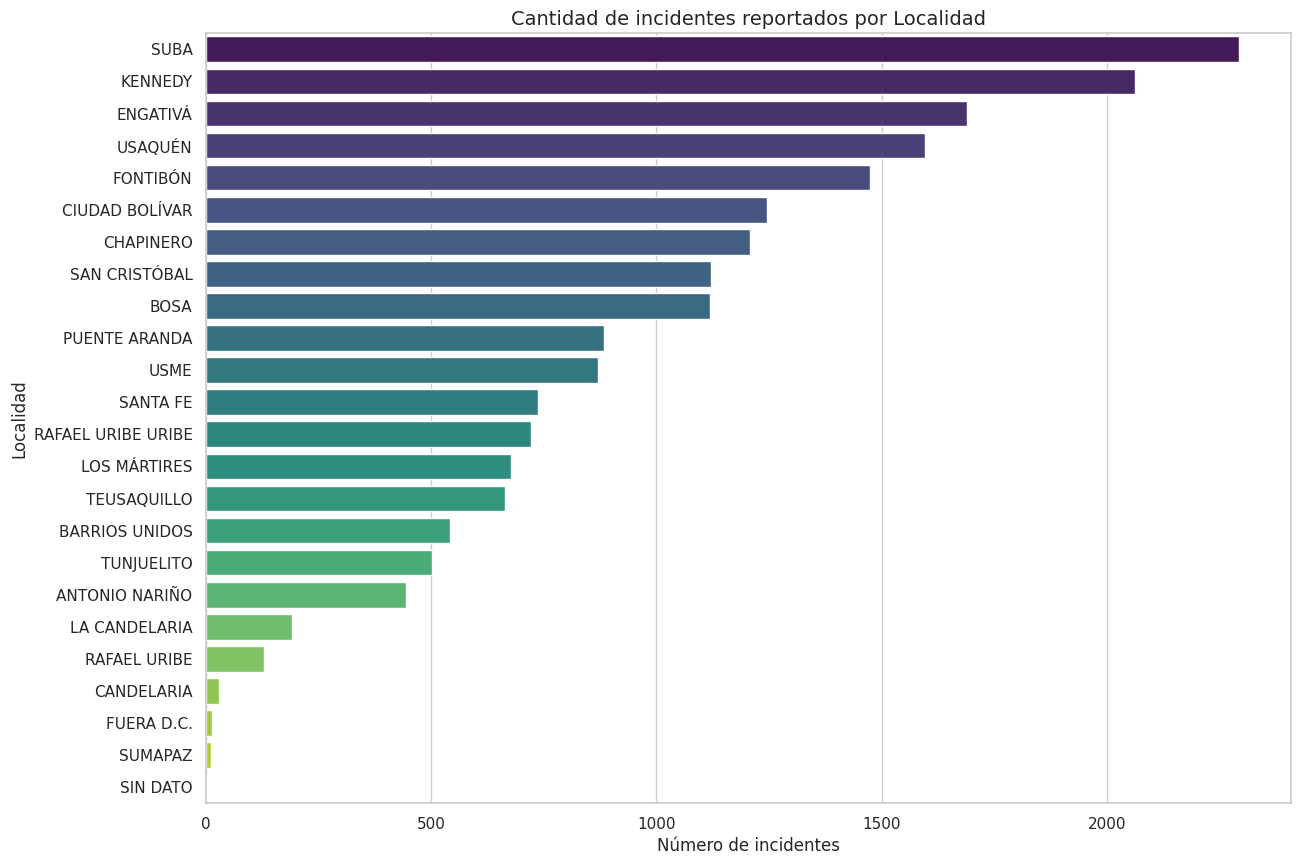

,Total Incidentes
LOCALIDAD,
SUBA,2293
KENNEDY,2061
ENGATIVÁ,1690
USAQUÉN,1596
FONTIBÓN,1473


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Establecer estilo visual
sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 10))
orden_localidades = df['LOCALIDAD'].value_counts().index
sns.countplot(data=df, y='LOCALIDAD', order=orden_localidades, palette='viridis')
plt.title('Cantidad de incidentes reportados por Localidad', fontsize=14)
plt.xlabel('Número de incidentes')
plt.ylabel('Localidad')
plt.show()

# Mostrar el top 5 en tabla
display(df['LOCALIDAD'].value_counts().to_frame('Total Incidentes').head())

/tmp/ipykernel_9966/1843959902.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='LOCALIDAD', order=orden_localidades, palette='viridis')


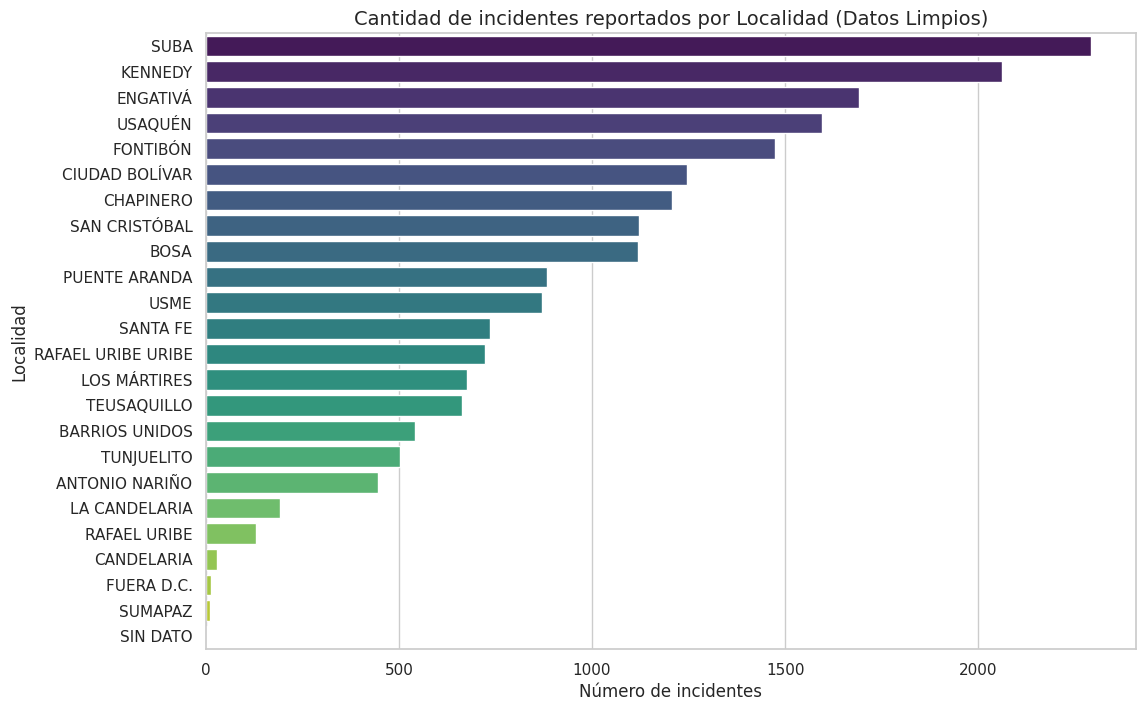

,Total Incidentes
LOCALIDAD,
SUBA,2293
KENNEDY,2061
ENGATIVÁ,1690
USAQUÉN,1596
FONTIBÓN,1473
CIUDAD BOLÍVAR,1246
CHAPINERO,1208
SAN CRISTÓBAL,1121
BOSA,1119


In [ ]:
# 3. Volver a graficar con los datos limpios
plt.figure(figsize=(12, 8))
orden_localidades = df['LOCALIDAD'].value_counts().index
sns.countplot(data=df, y='LOCALIDAD', order=orden_localidades, palette='viridis')
plt.title('Cantidad de incidentes reportados por Localidad (Datos Limpios)', fontsize=14)
plt.xlabel('Número de incidentes')
plt.ylabel('Localidad')
plt.show()

# Mostrar el top 10 en tabla con los datos unificados
display(df['LOCALIDAD'].value_counts().to_frame('Total Incidentes').head(10))

### **EDA - Pregunta 2: Tipos de servicio e Incendios**
¿Cuáles son los tipos de servicio más frecuentes y qué proporción representan los incendios?

/tmp/ipykernel_9966/3751344113.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='CLASE DE SERVICIO', order=orden_servicios, palette='magma')


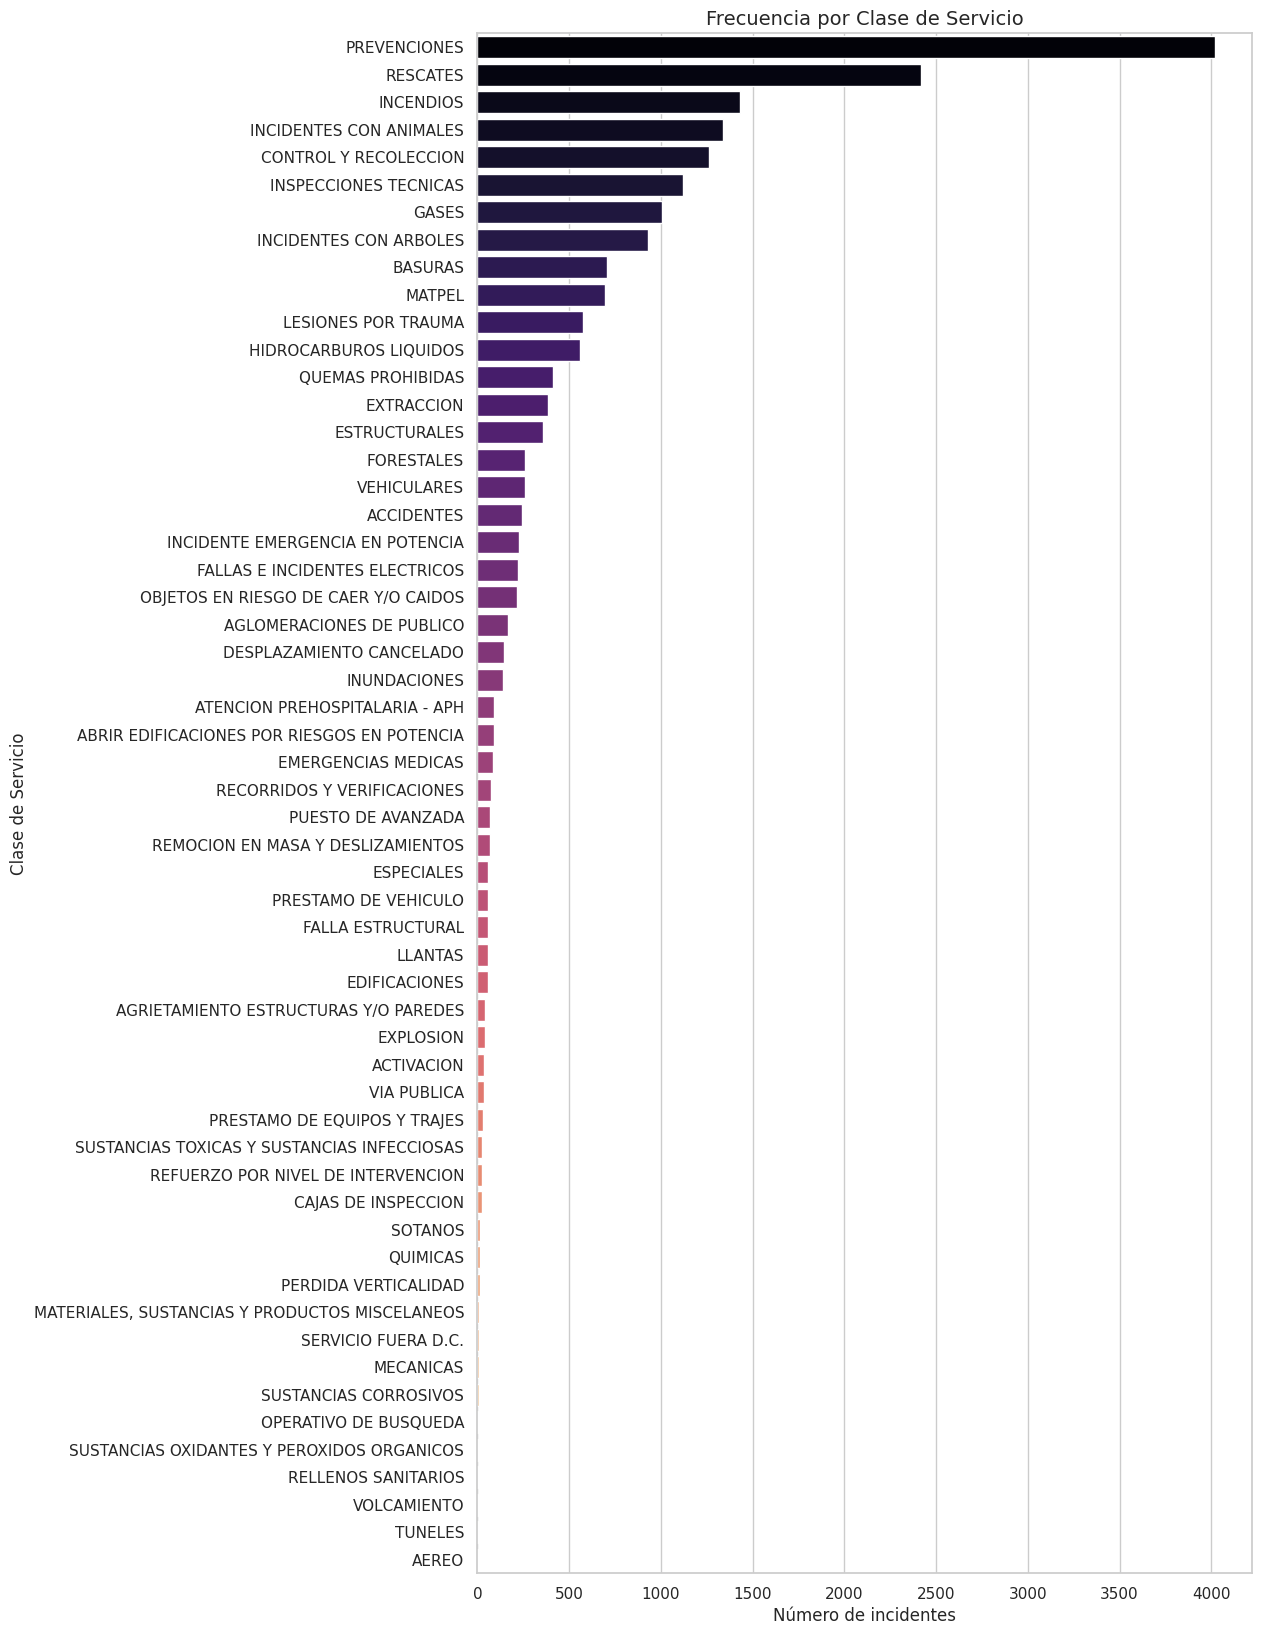

,Cantidad,Proporción (%)
CLASE DE SERVICIO,,
PREVENCIONES,4023,19.89
RESCATES,2419,11.96
INCENDIOS,1430,7.07
INCIDENTES CON ANIMALES,1337,6.61
CONTROL Y RECOLECCION,1261,6.23
INSPECCIONES TECNICAS,1120,5.54
GASES,1006,4.97
INCIDENTES CON ARBOLES,932,4.61
BASURAS,704,3.48


In [ ]:
plt.figure(figsize=(10, 20))
orden_servicios = df['CLASE DE SERVICIO'].value_counts().index
sns.countplot(data=df, y='CLASE DE SERVICIO', order=orden_servicios, palette='magma')
plt.title('Frecuencia por Clase de Servicio', fontsize=14)
plt.xlabel('Número de incidentes')
plt.ylabel('Clase de Servicio')
plt.show()

# Calcular la proporción de cada clase de servicio
proporcion_servicios = (df['CLASE DE SERVICIO'].value_counts(normalize=True) * 100).round(2)
tabla_servicios = df['CLASE DE SERVICIO'].value_counts().to_frame('Cantidad').join(
    proporcion_servicios.to_frame('Proporción (%)')
)
display(tabla_servicios)

### **EDA - Pregunta 3: Carga operativa y tiempos de respuesta por Estación**
¿Cuáles son las estaciones con mayor carga operativa y cuál es su tiempo promedio de respuesta?

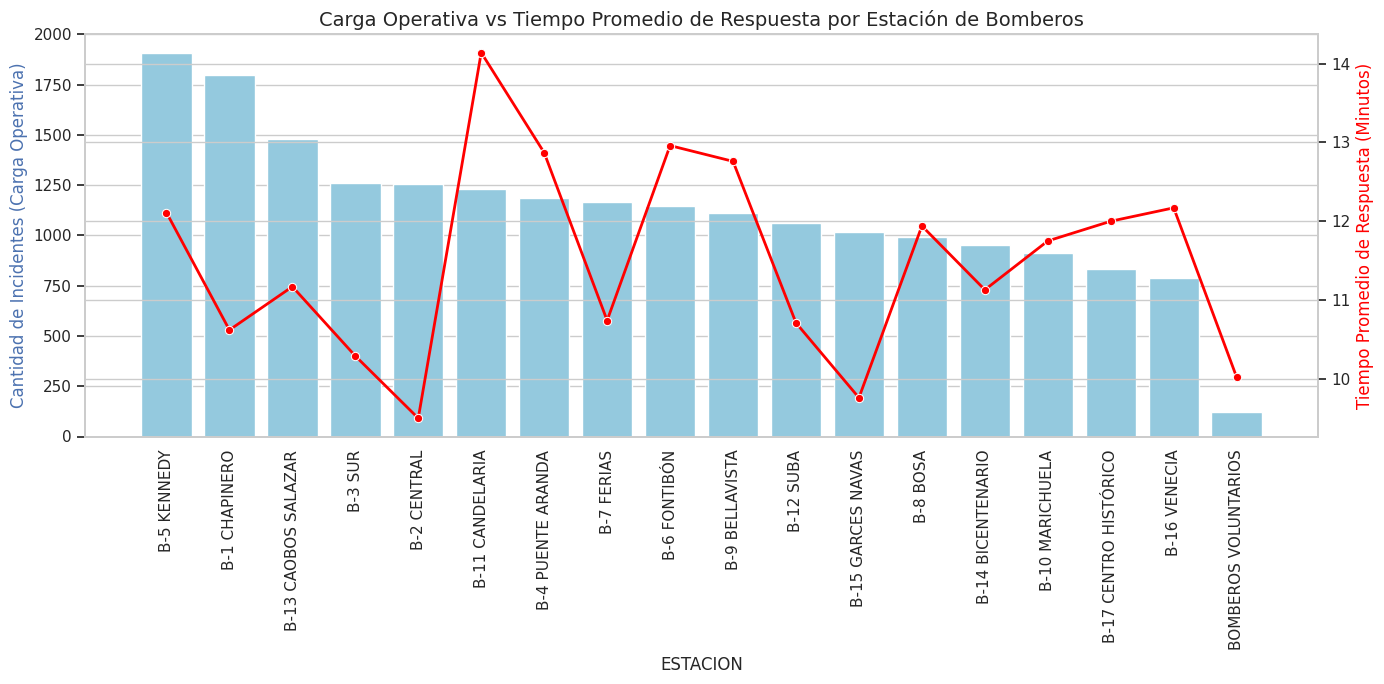

,Cantidad_Incidentes,Tiempo_Promedio_Min
ESTACION,,
B-5 KENNEDY,1905,12.11
B-1 CHAPINERO,1800,10.62
B-13 CAOBOS SALAZAR,1481,11.17
B-3 SUR,1262,10.29
B-2 CENTRAL,1256,9.50
B-11 CANDELARIA,1232,14.14
B-4 PUENTE ARANDA,1187,12.87
B-7 FERIAS,1167,10.74
B-6 FONTIBÓN,1148,12.96


In [20]:
# Función para unificar los nombres de las estaciones de bomberos
def limpiar_estacion(nombre):
  if pd.isna(nombre) or nombre == ' SIN DATO':
    return 'SIN DATO'

  nombre = str(nombre).upper().strip()

  # Unificar variaciones de bomberos voluntarios
  if 'VOLUNTARIO' in nombre or 'VOLUNTARIOS' in nombre:
    return 'BOMBEROS VOLUNTARIOS'

  return nombre


# Aplicar la limpieza a la columna de estaciones
df['ESTACION'] = df['ESTACION'].apply(limpiar_estacion)

# 1. Calcular carga operativa (conteo de incidentes por estación)
carga_estacion = df['ESTACION'].value_counts().to_frame('Cantidad_Incidentes')

# 2. Calcular tiempo promedio de respuesta por estación
tiempo_promedio = df.groupby('ESTACION')['Minutos_Respuesta'].mean().round(2).to_frame('Tiempo_Promedio_Min')

# 3. Unir y ordenar por carga operativa
stats_estaciones = carga_estacion.join(tiempo_promedio).sort_values(by='Cantidad_Incidentes', ascending=False)

# Crear gráfico combinado (Barras para carga operativa, Línea para tiempo promedio)
fig, ax1 = plt.subplots(figsize=(14, 7))

# Eje X e Y principal (Barras)
sns.barplot(x=stats_estaciones.index, y='Cantidad_Incidentes', data=stats_estaciones, ax=ax1, color='skyblue')
ax1.set_ylabel('Cantidad de Incidentes (Carga Operativa)', color='b')
ax1.tick_params(axis='x', rotation=90)

# Eje Y secundario (Línea)
ax2 = ax1.twinx()
sns.lineplot(x=stats_estaciones.index, y='Tiempo_Promedio_Min', data=stats_estaciones, ax=ax2, color='red', marker='o', linewidth=2)
ax2.set_ylabel('Tiempo Promedio de Respuesta (Minutos)', color='red')

plt.title('Carga Operativa vs Tiempo Promedio de Respuesta por Estación de Bomberos', fontsize=14)
plt.tight_layout()
plt.show()

# Mostrar el resumen estadístico de las estaciones
display(stats_estaciones.head(20))

### **2.4 Actividades de transferencia del conocimiento (Fase 3 - Consultas en SQL)**
Con el dataset limpio, se procede a cargarlo en un motor de base de datos relacional (SQLite integrado en Google Colab) para responder las tres (3) preguntas de negocio mediante consultas SQL.

In [21]:
import sqlite3

# 1. Crear la conexión a la base de datos SQLite en Colab y exportar el DataFrame limpio
conexion = sqlite3.connect('bomberos_uaecob.db')
df.to_sql('incidentes', conexion, if_exists='replace', index=False)
print(
    "Base de datos 'bomberos_uaecob.db' creada exitosamente con la tabla"
    " 'incidentes'.\n"
)


# PREGUNTA 1: ¿Cuáles son las localidades de Bogotá que concentran la mayor
#             cantidad de incidentes reportados?

sql_pregunta_1 = """
SELECT
    LOCALIDAD,
    COUNT(*) AS Total_Incidentes,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM incidentes), 2) AS Porcentaje
FROM incidentes
WHERE LOCALIDAD != 'SIN DATO'
GROUP BY LOCALIDAD
ORDER BY Total_Incidentes DESC
LIMIT 10;
"""
print(
    '--- RESULTADO SQL PREGUNTA 1: Top 10 Localidades con más incidentes ---'
)
df_sql1 = pd.read_sql_query(sql_pregunta_1, conexion)
display(df_sql1)



# PREGUNTA 2: ¿Cuáles son los tipos de servicio más frecuentes y qué proporción
#             representan los incendios?

# Parte A: Top 10 Clases de Servicio más frecuentes y su proporción (%)
sql_pregunta_2a = """
SELECT
    "CLASE DE SERVICIO" AS Clase_Servicio,
    COUNT(*) AS Cantidad,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM incidentes), 2) AS Proporcion_Porcentaje
FROM incidentes
GROUP BY "CLASE DE SERVICIO"
ORDER BY Cantidad DESC
LIMIT 10;
"""
print('\n--- RESULTADO SQL PREGUNTA 2 (Parte A): Top 10 Tipos de Servicio ---')
df_sql2a = pd.read_sql_query(sql_pregunta_2a, conexion)
display(df_sql2a)

# Parte B: Consulta específica para ver el peso de los INCENDIOS
sql_pregunta_2b = """
SELECT
    "CLASE DE SERVICIO" AS Categoria,
    COUNT(*) AS Total_Incendios,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM incidentes), 2) AS Proporcion_Del_Total_Porcentaje
FROM incidentes
WHERE "CLASE DE SERVICIO" = 'INCENDIOS';
"""
print(
    '\n--- RESULTADO SQL PREGUNTA 2 (Parte B): Proporción específica de'
    ' INCENDIOS ---'
)
df_sql2b = pd.read_sql_query(sql_pregunta_2b, conexion)
display(df_sql2b)



# PREGUNTA 3: ¿Cuáles son las estaciones con mayor carga operativa y cuál es su
#             tiempo promedio de respuesta?

sql_pregunta_3 = """
SELECT
    ESTACION,
    COUNT(*) AS Carga_Operativa_Incidentes,
    ROUND(AVG(Minutos_Respuesta), 2) AS Tiempo_Promedio_Minutos
FROM incidentes
WHERE ESTACION != 'SIN DATO'
GROUP BY ESTACION
ORDER BY Carga_Operativa_Incidentes DESC;
"""
print(
    '\n--- RESULTADO SQL PREGUNTA 3: Carga Operativa y Tiempo Promedio por'
    ' Estación ---'
)
df_sql3 = pd.read_sql_query(sql_pregunta_3, conexion)
display(df_sql3)

# Cerrar la conexión de forma segura
conexion.close()

Base de datos 'bomberos_uaecob.db' creada exitosamente con la tabla 'incidentes'.

--- RESULTADO SQL PREGUNTA 1: Top 10 Localidades con más incidentes ---


,LOCALIDAD,Total_Incidentes,Porcentaje
0,SUBA,2293,11.34
1,KENNEDY,2061,10.19
2,ENGATIVÁ,1690,8.35
3,USAQUÉN,1596,7.89
4,FONTIBÓN,1473,7.28
5,CIUDAD BOLÍVAR,1246,6.16
6,CHAPINERO,1208,5.97
7,SAN CRISTÓBAL,1121,5.54
8,BOSA,1119,5.53
9,PUENTE ARANDA,883,4.37



--- RESULTADO SQL PREGUNTA 2 (Parte A): Top 10 Tipos de Servicio ---


,Clase_Servicio,Cantidad,Proporcion_Porcentaje
0,PREVENCIONES,4023,19.89
1,RESCATES,2419,11.96
2,INCENDIOS,1430,7.07
3,INCIDENTES CON ANIMALES,1337,6.61
4,CONTROL Y RECOLECCION,1261,6.23
5,INSPECCIONES TECNICAS,1120,5.54
6,GASES,1006,4.97
7,INCIDENTES CON ARBOLES,932,4.61
8,BASURAS,704,3.48
9,MATPEL,698,3.45



--- RESULTADO SQL PREGUNTA 2 (Parte B): Proporción específica de INCENDIOS ---


,Categoria,Total_Incendios,Proporcion_Del_Total_Porcentaje
0,INCENDIOS,1430,7.07



--- RESULTADO SQL PREGUNTA 3: Carga Operativa y Tiempo Promedio por Estación ---


,ESTACION,Carga_Operativa_Incidentes,Tiempo_Promedio_Minutos
0,B-5 KENNEDY,1905,12.11
1,B-1 CHAPINERO,1800,10.62
2,B-13 CAOBOS SALAZAR,1481,11.17
3,B-3 SUR,1262,10.29
4,B-2 CENTRAL,1256,9.50
5,B-11 CANDELARIA,1232,14.14
6,B-4 PUENTE ARANDA,1187,12.87
7,B-7 FERIAS,1167,10.74
8,B-6 FONTIBÓN,1148,12.96
9,B-9 BELLAVISTA,1110,12.76


In [22]:
# 1. Exportar el DataFrame limpio a un archivo CSV
nombre_archivo_csv = 'incidentes_bomberos_limpio.csv'
df.to_csv(nombre_archivo_csv, index=False, encoding='utf-8-sig')
print(f"Dataset exportado exitosamente como CSV: '{nombre_archivo_csv}'")

Dataset exportado exitosamente como CSV: 'incidentes_bomberos_limpio.csv'
